
#  PINN para la ecuación de ondas bidimensional

## 1. Planteamiento del problema

Se estudia una membrana cuadrada de lado unitario y bordes fijos, cuyo desplazamiento transversal satisface la ecuación de ondas:

$$
\frac{\partial^2 U}{\partial t^2}
=
\frac{\partial^2 U}{\partial x^2}
+
\frac{\partial^2 U}{\partial y^2}.
$$

Las condiciones iniciales son:

$$
U(x,y,0)=\sin(\pi x)\sin(\pi y),
$$

$$
U_t(x,y,0)=\sqrt{2}\pi\sin(\pi x)\sin(\pi y).
$$

Se propone una aproximación PINN de la forma:

$$
U_\theta(x,y,t)=\sin(\pi x)\sin(\pi y)a_\theta(t).
$$

Al sustituir esta expresión en la ecuación de ondas, el problema se reduce a:

$$
a_\theta''(t)+2\pi^2a_\theta(t)=0,
$$

con condiciones iniciales:

$$
a_\theta(0)=1,
\qquad
a_\theta'(0)=\sqrt{2}\pi.
$$

Se implementarán dos arquitecturas neuronales con activaciones sinusoidales. Ambas se entrenarán minimizando el residuo físico y los errores en las condiciones iniciales. Finalmente, se compararán sus predicciones con la solución exacta y se analizará la conservación de la energía mecánica.


In [1]:

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Semillas para reproducibilidad
np.random.seed(42)
torch.manual_seed(42)

# Precisión numérica
torch.set_default_dtype(torch.float64)

# Dispositivo de cálculo
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Frecuencia natural de la membrana
omega = np.sqrt(2) * np.pi

print(f"PyTorch: {torch.__version__}")
print(f"Dispositivo: {device}")
print(f"Frecuencia natural: {omega:.6f}")


PyTorch: 2.11.0+cpu
Dispositivo: cpu
Frecuencia natural: 4.442883



## 2. Solución analítica exacta

La ecuación diferencial que describe la amplitud temporal de la membrana es:

$$
a''(t)+2\pi^2a(t)=0.
$$

Con las condiciones iniciales:

$$
a(0)=1,\qquad a'(0)=\sqrt{2}\pi.
$$

Su solución exacta es:

$$
a(t)=\cos(\sqrt{2}\pi t)+\sin(\sqrt{2}\pi t).
$$

Por tanto, el desplazamiento de la membrana es:

$$
U(x,y,t)=\sin(\pi x)\sin(\pi y)
\left[\cos(\sqrt{2}\pi t)+\sin(\sqrt{2}\pi t)\right].
$$

Esta solución permitirá comprobar las condiciones iniciales, visualizar las oscilaciones y cuantificar posteriormente los errores de las redes neuronales.


In [2]:

# Solución temporal exacta
def a_exacta(t):
    return np.cos(omega * t) + np.sin(omega * t)

# Primera derivada temporal
def da_exacta(t):
    return omega * (
        np.cos(omega * t) - np.sin(omega * t)
    )

# Segunda derivada temporal
def d2a_exacta(t):
    return -(omega**2) * a_exacta(t)

# Desplazamiento exacto de la membrana
def U_exacta(x, y, t):
    return (
        np.sin(np.pi * x)
        * np.sin(np.pi * y)
        * a_exacta(t)
    )

# Verificación de las condiciones iniciales
a0 = a_exacta(0.0)
da0 = da_exacta(0.0)

# Verificación del residuo de la EDO
t_test = np.linspace(0, 3, 500)
residuo = d2a_exacta(t_test) + omega**2 * a_exacta(t_test)

print(f"a(0) = {a0:.8f}")
print(f"a'(0) = {da0:.8f}")
print(f"Valor esperado de a'(0) = {omega:.8f}")
print(f"Residuo máximo = {np.max(np.abs(residuo)):.3e}")

assert np.isclose(a0, 1.0)
assert np.isclose(da0, omega)
assert np.max(np.abs(residuo)) < 1e-12


a(0) = 1.00000000
a'(0) = 4.44288294
Valor esperado de a'(0) = 4.44288294
Residuo máximo = 0.000e+00



## 3. Modelo A: red neuronal con dos activaciones sinusoidales

El primer modelo aproxima la amplitud temporal mediante una suma de dos funciones sinusoidales:

$$
a_\theta(t)=\sum_{j=1}^{2}A_j\sin(w_jt+b_j).
$$

Los parámetros entrenables son las amplitudes $A_j$, las frecuencias $w_j$ y los sesgos $b_j$.

Para entrenar esta red mediante una PINN, utilizaremos la ecuación diferencial:

$$
a_\theta''(t)+2\pi^2a_\theta(t)=0.
$$

La arquitectura permite representar exactamente la solución analítica, ya que esta es una combinación de seno y coseno con la misma frecuencia angular.


In [3]:

class ModeloA(nn.Module):
    def __init__(self):
        super().__init__()

        # Parámetros entrenables de las dos neuronas
        self.A = nn.Parameter(
            torch.tensor([0.8, 0.8], dtype=torch.float64)
        )

        self.w = nn.Parameter(
            torch.tensor([3.5, 5.0], dtype=torch.float64)
        )

        self.b = nn.Parameter(
            torch.tensor([0.5, 0.0], dtype=torch.float64)
        )

    def forward(self, t):
        # t tiene dimensiones (N, 1)
        # Cada columna representa una neurona sinusoidal
        z = t * self.w + self.b

        # Suma de las dos contribuciones neuronales
        a = torch.sum(
            self.A * torch.sin(z),
            dim=1,
            keepdim=True
        )

        return a


# Instanciamos el modelo
modelo_A = ModeloA().to(device)

# Verificamos su funcionamiento
t_prueba = torch.linspace(
    0, 3, 100, device=device
).reshape(-1, 1)

a_prueba = modelo_A(t_prueba)

print("Dimensiones de entrada:", t_prueba.shape)
print("Dimensiones de salida:", a_prueba.shape)

print("\nParámetros iniciales:")
for nombre, parametro in modelo_A.named_parameters():
    print(nombre, parametro.detach().cpu().numpy())


Dimensiones de entrada: torch.Size([100, 1])
Dimensiones de salida: torch.Size([100, 1])

Parámetros iniciales:
A [0.8 0.8]
w [3.5 5. ]
b [0.5 0. ]



### 3.1. Residuo físico y diferenciación automática

Una PINN incorpora la ecuación diferencial dentro de su función de pérdida.

Para el Modelo A, definimos el residuo:

$$
r_\theta(t)=a_\theta''(t)+2\pi^2a_\theta(t).
$$

Si la red satisface exactamente la ecuación de ondas reducida, el residuo debe ser cero.

Las derivadas temporales se calcularán mediante diferenciación automática de PyTorch, conservando el grafo computacional para poder optimizar los parámetros de la red.


In [4]:

def calcular_residuo(modelo, t):
    # Habilitamos derivadas respecto al tiempo
    t = t.clone().detach().requires_grad_(True)

    # Predicción de la amplitud temporal
    a = modelo(t)

    # Primera derivada temporal
    da_dt = torch.autograd.grad(
        outputs=a,
        inputs=t,
        grad_outputs=torch.ones_like(a),
        create_graph=True
    )[0]

    # Segunda derivada temporal
    d2a_dt2 = torch.autograd.grad(
        outputs=da_dt,
        inputs=t,
        grad_outputs=torch.ones_like(da_dt),
        create_graph=True
    )[0]

    # Residuo de la ecuación diferencial
    residuo = d2a_dt2 + (omega**2) * a

    return residuo


# Puntos temporales para comprobar el residuo inicial
t_residuo = torch.linspace(
    0, 3, 200, device=device
).reshape(-1, 1)

r_inicial = calcular_residuo(modelo_A, t_residuo)

print(
    "Error cuadrático medio inicial del residuo:",
    torch.mean(r_inicial**2).item()
)


Error cuadrático medio inicial del residuo: 29.71832490675437



### 3.2. Función de pérdida del Modelo A

Para entrenar la PINN, se minimiza una función de pérdida que combina el cumplimiento de la ecuación diferencial y de las condiciones iniciales.

La pérdida física se define como:

$$
\mathcal{L}_{fis}=
\frac{1}{N_r}\sum_{k=1}^{N_r}
\left[a_\theta''(t_k)+2\pi^2a_\theta(t_k)\right]^2.
$$

Las condiciones iniciales generan dos términos adicionales:

$$
\mathcal{L}_{CI,1}=[a_\theta(0)-1]^2,
$$

$$
\mathcal{L}_{CI,2}=[a_\theta'(0)-\sqrt{2}\pi]^2.
$$

La función de pérdida total es:

$$
\mathcal{L}=
\lambda_r\mathcal{L}_{fis}
+\lambda_0\mathcal{L}_{CI,1}
+\lambda_1\mathcal{L}_{CI,2}.
$$

Inicialmente se utilizarán pesos unitarios. Durante el entrenamiento se buscarán los parámetros que minimicen simultáneamente las tres contribuciones.


In [5]:

def funcion_perdida(modelo, t_colocacion,
                    lambda_r=1.0,
                    lambda_0=1.0,
                    lambda_1=1.0):

    # 1. Pérdida asociada a la ecuación diferencial
    residuo = calcular_residuo(modelo, t_colocacion)
    perdida_fisica = torch.mean(residuo**2)

    # 2. Condiciones iniciales en t = 0
    t0 = torch.zeros(
        (1, 1),
        dtype=torch.float64,
        device=device,
        requires_grad=True
    )

    a0 = modelo(t0)

    # Primera derivada temporal en t = 0
    da0 = torch.autograd.grad(
        outputs=a0,
        inputs=t0,
        grad_outputs=torch.ones_like(a0),
        create_graph=True
    )[0]

    # 3. Errores en las condiciones iniciales
    perdida_ci1 = torch.mean((a0 - 1.0)**2)
    perdida_ci2 = torch.mean((da0 - omega)**2)

    # 4. Pérdida total
    perdida_total = (
        lambda_r * perdida_fisica
        + lambda_0 * perdida_ci1
        + lambda_1 * perdida_ci2
    )

    return (
        perdida_total,
        perdida_fisica,
        perdida_ci1,
        perdida_ci2
    )


# Evaluación inicial de la pérdida
perdidas = funcion_perdida(modelo_A, t_residuo)

print(f"Pérdida total inicial: {perdidas[0].item():.6e}")
print(f"Pérdida física:        {perdidas[1].item():.6e}")
print(f"Condición a(0):        {perdidas[2].item():.6e}")
print(f"Condición a'(0):       {perdidas[3].item():.6e}")


Pérdida total inicial: 3.415595e+01
Pérdida física:        2.971832e+01
Condición a(0):        3.800224e-01
Condición a'(0):       4.057599e+00



### 3.3. Entrenamiento del Modelo A

Los parámetros del Modelo A se optimizarán mediante el algoritmo Adam.

En cada iteración se evalúa la función de pérdida, se calculan sus gradientes mediante retropropagación y se actualizan los parámetros de la red.

Se utilizarán puntos de colocación distribuidos uniformemente en el intervalo temporal $t\in[0,3]$.

Durante el entrenamiento se almacenarán las pérdidas para analizar la convergencia del modelo.


In [6]:

# Puntos de colocación
t_train = torch.linspace(
    0, 3, 200,
    dtype=torch.float64,
    device=device
).reshape(-1, 1)

# Optimizador
optimizador_A = torch.optim.Adam(
    modelo_A.parameters(),
    lr=0.01
)

# Configuración
epocas = 5000

# Historial
historial_A = {
    "total": [],
    "fisica": [],
    "ci1": [],
    "ci2": []
}

# Entrenamiento
for epoca in range(epocas):

    optimizador_A.zero_grad()

    total, fisica, ci1, ci2 = funcion_perdida(
        modelo_A, t_train
    )

    total.backward()
    optimizador_A.step()

    # Guardar pérdidas
    historial_A["total"].append(total.item())
    historial_A["fisica"].append(fisica.item())
    historial_A["ci1"].append(ci1.item())
    historial_A["ci2"].append(ci2.item())

    if (epoca + 1) % 500 == 0:
        print(
            f"Época {epoca+1:5d} | "
            f"Total: {total.item():.3e} | "
            f"Física: {fisica.item():.3e} | "
            f"CI: {(ci1+ci2).item():.3e}"
        )

print("\nEntrenamiento del Modelo A finalizado.")

print("\nParámetros entrenados:")
for nombre, parametro in modelo_A.named_parameters():
    print(
        nombre,
        parametro.detach().cpu().numpy()
    )


Época   500 | Total: 8.605e-03 | Física: 7.351e-03 | CI: 1.254e-03
Época  1000 | Total: 1.226e-03 | Física: 1.222e-03 | CI: 3.205e-06
Época  1500 | Total: 3.754e-04 | Física: 3.749e-04 | CI: 5.825e-07
Época  2000 | Total: 1.440e-04 | Física: 1.438e-04 | CI: 1.263e-07
Época  2500 | Total: 6.330e-05 | Física: 6.327e-05 | CI: 3.432e-08
Época  3000 | Total: 3.043e-05 | Física: 3.042e-05 | CI: 1.087e-08
Época  3500 | Total: 1.555e-05 | Física: 1.554e-05 | CI: 3.821e-09
Época  4000 | Total: 8.295e-06 | Física: 8.294e-06 | CI: 1.446e-09
Época  4500 | Total: 4.566e-06 | Física: 4.566e-06 | CI: 5.769e-10
Época  5000 | Total: 2.572e-06 | Física: 2.572e-06 | CI: 2.394e-10

Entrenamiento del Modelo A finalizado.

Parámetros entrenados:
A [0.56311997 0.8515939 ]
w [4.42555326 4.45429422]
b [0.81968449 0.7628101 ]



### 3.4. Análisis de convergencia

Se representa la evolución de la función de pérdida total y de sus componentes durante el entrenamiento.

Una disminución sostenida indica que la red mejora el cumplimiento de la ecuación diferencial y de las condiciones iniciales.

Se utiliza una escala logarítmica para visualizar las pérdidas incluso cuando alcanzan valores pequeños.


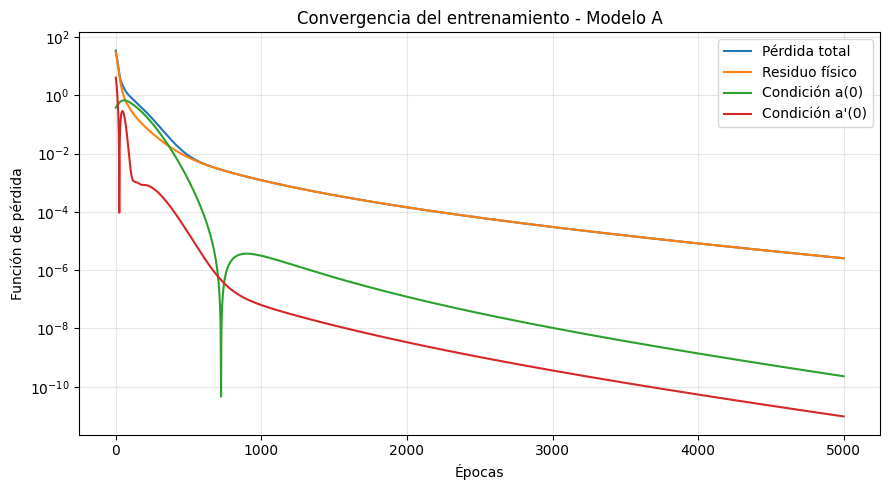

In [7]:

plt.figure(figsize=(9, 5))

plt.semilogy(
    historial_A["total"],
    label="Pérdida total"
)

plt.semilogy(
    historial_A["fisica"],
    label="Residuo físico"
)

plt.semilogy(
    historial_A["ci1"],
    label="Condición a(0)"
)

plt.semilogy(
    historial_A["ci2"],
    label="Condición a'(0)"
)

plt.xlabel("Épocas")
plt.ylabel("Función de pérdida")
plt.title("Convergencia del entrenamiento - Modelo A")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### 3.5. Comparación entre la PINN y la solución analítica

Una vez entrenado el Modelo A, se compara su predicción temporal con la solución exacta:

$$
a(t)=\cos(\sqrt{2}\pi t)+\sin(\sqrt{2}\pi t).
$$

Se representan ambas soluciones en el intervalo $t\in[0,3]$, junto con el error absoluto:

$$
e(t)=|a_\theta(t)-a(t)|.
$$

Esta comparación permite evaluar directamente la capacidad de aproximación del modelo, más allá de la disminución de la función de pérdida durante el entrenamiento.


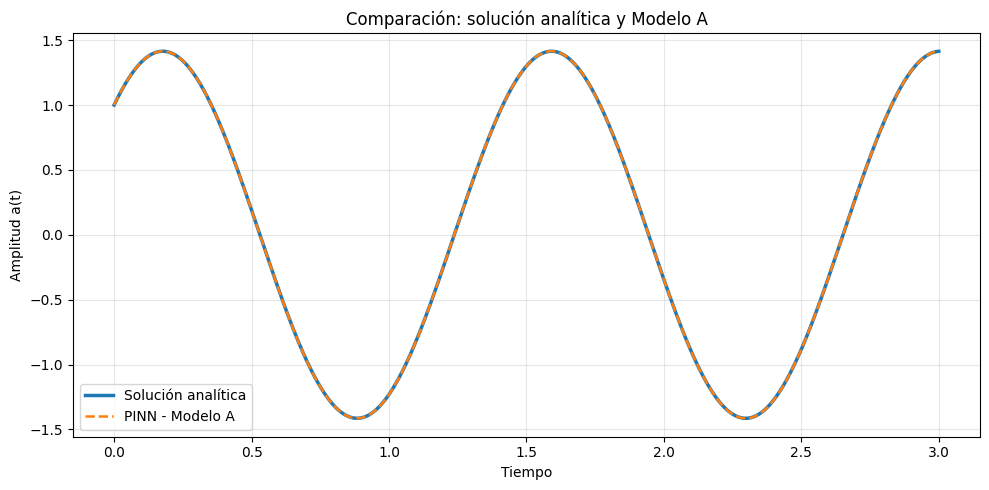

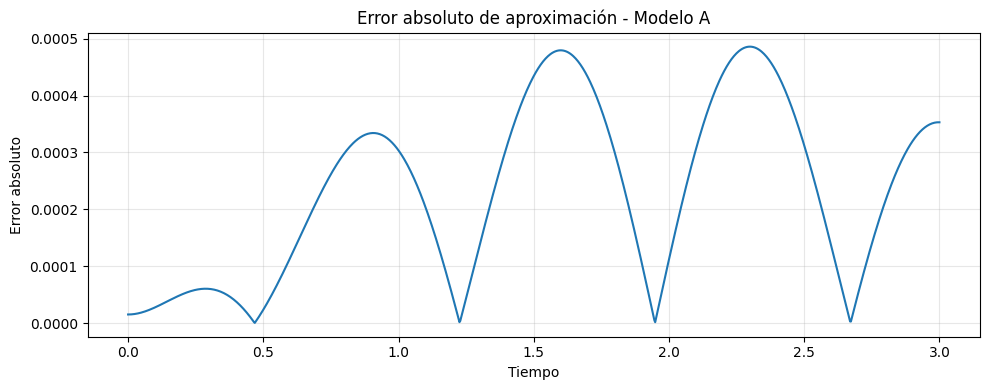

In [8]:

# Malla temporal de evaluación
t_eval = np.linspace(0, 3, 1000)

# Solución exacta
a_real = a_exacta(t_eval)

# Predicción del Modelo A
t_tensor = torch.tensor(
    t_eval.reshape(-1, 1),
    dtype=torch.float64,
    device=device
)

modelo_A.eval()

with torch.no_grad():
    a_pred = (
        modelo_A(t_tensor)
        .cpu()
        .numpy()
        .flatten()
    )

# Error absoluto
error_abs = np.abs(a_pred - a_real)

# Gráfica comparativa
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    t_eval, a_real,
    label="Solución analítica",
    linewidth=2.5
)

ax.plot(
    t_eval, a_pred,
    "--",
    label="PINN - Modelo A",
    linewidth=1.8
)

ax.set_xlabel("Tiempo")
ax.set_ylabel("Amplitud a(t)")
ax.set_title("Comparación: solución analítica y Modelo A")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Gráfica del error absoluto
plt.figure(figsize=(10, 4))

plt.plot(t_eval, error_abs)

plt.xlabel("Tiempo")
plt.ylabel("Error absoluto")
plt.title("Error absoluto de aproximación - Modelo A")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



### 3.6. Cuantificación del error de aproximación

Para evaluar cuantitativamente la precisión del Modelo A, se calculan tres métricas:

**Error absoluto medio (MAE):**

$$
MAE=\frac{1}{N}\sum_{i=1}^{N}|a_\theta(t_i)-a(t_i)|.
$$

**Raíz del error cuadrático medio (RMSE):**

$$
RMSE=\sqrt{\frac{1}{N}\sum_{i=1}^{N}[a_\theta(t_i)-a(t_i)]^2}.
$$

**Error relativo global:**

$$
E_{rel}=
\frac{\sqrt{\sum_i[a_\theta(t_i)-a(t_i)]^2}}
{\sqrt{\sum_i a(t_i)^2}}\times100\%.
$$

Estas métricas permiten medir la diferencia entre la predicción de la PINN y la solución exacta. El error relativo global evita las divisiones por valores individuales de la solución que pueden ser cercanos a cero.


In [9]:

# Errores de aproximación del Modelo A
diferencia_A = a_pred - a_real

mae_A = np.mean(np.abs(diferencia_A))

rmse_A = np.sqrt(
    np.mean(diferencia_A**2)
)

error_relativo_A = (
    np.linalg.norm(diferencia_A)
    / np.linalg.norm(a_real)
) * 100

error_maximo_A = np.max(np.abs(diferencia_A))

print("RESULTADOS DEL MODELO A")
print("-" * 40)
print(f"MAE:                  {mae_A:.8e}")
print(f"RMSE:                 {rmse_A:.8e}")
print(f"Error relativo global: {error_relativo_A:.6f} %")
print(f"Error absoluto máximo: {error_maximo_A:.8e}")


RESULTADOS DEL MODELO A
----------------------------------------
MAE:                  2.29397612e-04
RMSE:                 2.75928740e-04
Error relativo global: 0.027106 %
Error absoluto máximo: 4.86034559e-04



### 3.7. Conservación de la energía mecánica

Para evaluar la consistencia física del Modelo A, se calcula la energía mecánica de la membrana:

$$
E(t)=\frac18[a'(t)]^2+\frac{\pi^2}{4}[a(t)]^2.
$$

La solución exacta conserva la energía:

$$
E_{\mathrm{exacta}}=\frac{\pi^2}{2}.
$$

Se calculará la derivada temporal de la amplitud mediante diferenciación automática y se comparará la energía predicha por la PINN con el valor teórico.

Una energía aproximadamente constante indicará que el modelo reproduce adecuadamente la dinámica conservativa del sistema.


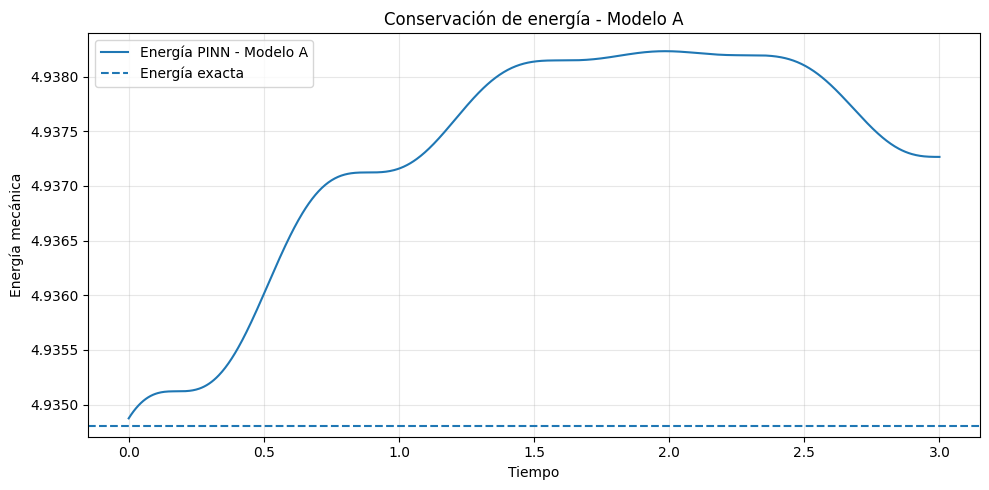

Energía exacta: 4.93480220
Energía media PINN: 4.93729810
Error relativo medio de energía: 0.050578 %
Error relativo máximo de energía: 0.069495 %
Variación relativa de energía: 0.068050 %


In [10]:

# Puntos temporales para evaluar la energía
t_energia = torch.linspace(
    0, 3, 1000,
    dtype=torch.float64,
    device=device
).reshape(-1, 1).requires_grad_(True)

# Amplitud predicha
a_energia = modelo_A(t_energia)

# Derivada temporal mediante autograd
da_energia = torch.autograd.grad(
    outputs=a_energia,
    inputs=t_energia,
    grad_outputs=torch.ones_like(a_energia),
    create_graph=False
)[0]

# Energía predicha por el Modelo A
E_A = (
    (1 / 8) * da_energia**2
    + (np.pi**2 / 4) * a_energia**2
)

E_A = E_A.detach().cpu().numpy().flatten()

# Energía teórica
E_exacta = np.pi**2 / 2

# Error relativo de energía
error_energia_A = (
    np.abs(E_A - E_exacta) / E_exacta
) * 100

# Gráfica
plt.figure(figsize=(10, 5))

plt.plot(
    t_eval,
    E_A,
    label="Energía PINN - Modelo A"
)

plt.axhline(
    E_exacta,
    linestyle="--",
    label="Energía exacta"
)

plt.xlabel("Tiempo")
plt.ylabel("Energía mecánica")
plt.title("Conservación de energía - Modelo A")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Energía exacta: {E_exacta:.8f}")
print(f"Energía media PINN: {np.mean(E_A):.8f}")
print(
    f"Error relativo medio de energía: "
    f"{np.mean(error_energia_A):.6f} %"
)
print(
    f"Error relativo máximo de energía: "
    f"{np.max(error_energia_A):.6f} %"
)
print(
    f"Variación relativa de energía: "
    f"{(np.max(E_A)-np.min(E_A))/E_exacta*100:.6f} %"
)



## 4. Modelo B: red neuronal de dos capas sinusoidales

El segundo modelo utiliza dos capas consecutivas, cada una con una neurona de activación sinusoidal.

La primera capa calcula:

$$
h_1(t)=\sin(w_1t+b_1).
$$

La segunda capa produce:

$$
a_\theta(t)=A\sin(w_2h_1(t)+b_2).
$$

Por tanto, la amplitud temporal queda expresada como:

$$
a_\theta(t)=A\sin[w_2\sin(w_1t+b_1)+b_2].
$$

El objetivo es entrenar sus cinco parámetros para minimizar el residuo de la ecuación diferencial y los errores en las condiciones iniciales.

Posteriormente, se comparará su precisión y conservación de energía con las del Modelo A.


In [11]:

class ModeloB(nn.Module):
    def __init__(self):
        super().__init__()

        # Parámetros entrenables
        self.A = nn.Parameter(
            torch.tensor(1.5, dtype=torch.float64)
        )

        self.w1 = nn.Parameter(
            torch.tensor(4.0, dtype=torch.float64)
        )

        self.w2 = nn.Parameter(
            torch.tensor(1.5, dtype=torch.float64)
        )

        self.b1 = nn.Parameter(
            torch.tensor(0.0, dtype=torch.float64)
        )

        self.b2 = nn.Parameter(
            torch.tensor(0.5, dtype=torch.float64)
        )

    def forward(self, t):

        # Primera capa
        h1 = torch.sin(self.w1 * t + self.b1)

        # Segunda capa
        a = self.A * torch.sin(
            self.w2 * h1 + self.b2
        )

        return a


# Instanciar el Modelo B
modelo_B = ModeloB().to(device)

# Verificar la salida
t_prueba_B = torch.linspace(
    0, 3, 100,
    dtype=torch.float64,
    device=device
).reshape(-1, 1)

a_prueba_B = modelo_B(t_prueba_B)

print("Dimensiones de entrada:", t_prueba_B.shape)
print("Dimensiones de salida:", a_prueba_B.shape)

print("\nParámetros iniciales del Modelo B:")

for nombre, parametro in modelo_B.named_parameters():
    print(nombre, parametro.detach().cpu().numpy())


Dimensiones de entrada: torch.Size([100, 1])
Dimensiones de salida: torch.Size([100, 1])

Parámetros iniciales del Modelo B:
A 1.5
w1 4.0
w2 1.5
b1 0.0
b2 0.5



### 4.1. Entrenamiento del Modelo B

El Modelo B se entrenará minimizando la función de pérdida física:

$$
\mathcal{L}=
\lambda_r\mathcal{L}_{fis}
+\lambda_0\mathcal{L}_{CI,1}
+\lambda_1\mathcal{L}_{CI,2}.
$$

El residuo de la ecuación diferencial es:

$$
r_\theta(t)=a_\theta''(t)+2\pi^2a_\theta(t).
$$

Las condiciones iniciales que debe satisfacer son:

$$
a_\theta(0)=1,
\qquad
a_\theta'(0)=\sqrt{2}\pi.
$$

Se utilizará el optimizador Adam durante 5000 épocas, con los mismos puntos de colocación y pesos de pérdida del Modelo A.

Esto permitirá comparar el comportamiento de ambas arquitecturas bajo condiciones de entrenamiento equivalentes.


In [12]:

# Optimizador del Modelo B
optimizador_B = torch.optim.Adam(
    modelo_B.parameters(),
    lr=0.01
)

# Número de épocas
epocas_B = 5000

# Historial de pérdidas
historial_B = {
    "total": [],
    "fisica": [],
    "ci1": [],
    "ci2": []
}

# Entrenamiento
modelo_B.train()

for epoca in range(epocas_B):

    optimizador_B.zero_grad()

    # Función de pérdida
    total, fisica, ci1, ci2 = funcion_perdida(
        modelo_B,
        t_train,
        lambda_r=1.0,
        lambda_0=1.0,
        lambda_1=1.0
    )

    # Retropropagación
    total.backward()

    # Actualización de parámetros
    optimizador_B.step()

    # Guardar historial
    historial_B["total"].append(total.item())
    historial_B["fisica"].append(fisica.item())
    historial_B["ci1"].append(ci1.item())
    historial_B["ci2"].append(ci2.item())

    # Mostrar avance
    if (epoca + 1) % 500 == 0:
        print(
            f"Época {epoca+1:5d} | "
            f"Total: {total.item():.3e} | "
            f"Física: {fisica.item():.3e} | "
            f"CI: {(ci1 + ci2).item():.3e}"
        )

print("\nEntrenamiento del Modelo B finalizado.")

print("\nParámetros entrenados:")

for nombre, parametro in modelo_B.named_parameters():
    print(
        nombre,
        parametro.detach().cpu().numpy()
    )


Época   500 | Total: 4.959e+00 | Física: 1.943e+00 | CI: 3.016e+00
Época  1000 | Total: 3.190e+00 | Física: 1.337e+00 | CI: 1.853e+00
Época  1500 | Total: 2.197e+00 | Física: 9.981e-01 | CI: 1.199e+00
Época  2000 | Total: 1.617e+00 | Física: 7.721e-01 | CI: 8.446e-01
Época  2500 | Total: 1.245e+00 | Física: 6.184e-01 | CI: 6.268e-01
Época  3000 | Total: 9.871e-01 | Física: 5.090e-01 | CI: 4.781e-01
Época  3500 | Total: 7.964e-01 | Física: 4.272e-01 | CI: 3.692e-01
Época  4000 | Total: 6.493e-01 | Física: 3.631e-01 | CI: 2.862e-01
Época  4500 | Total: 5.325e-01 | Física: 3.112e-01 | CI: 2.213e-01
Época  5000 | Total: 4.380e-01 | Física: 2.678e-01 | CI: 1.702e-01

Entrenamiento del Modelo B finalizado.

Parámetros entrenados:
A 3.713188943475295
w1 4.4417664311896585
w2 0.31183723742076325
b1 0.5558613694857581
b2 0.00040146722938589426



### 4.2. Convergencia del Modelo B

Se analiza la evolución de la función de pérdida total, el residuo físico y los errores asociados a las condiciones iniciales.

La representación en escala logarítmica permite observar la reducción de los errores durante las 5000 épocas.

La convergencia obtenida se comparará posteriormente con la del Modelo A para evaluar las diferencias entre las dos arquitecturas.


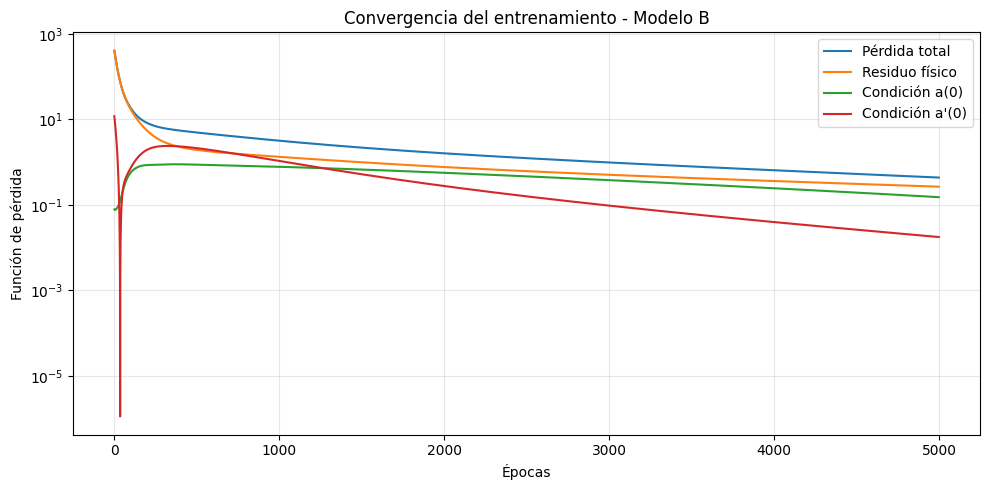

PÉRDIDAS FINALES DEL MODELO B
------------------------------------------
total     : 4.37972929e-01
fisica    : 2.67782829e-01
ci1       : 1.52397040e-01
ci2       : 1.77930603e-02


In [13]:

plt.figure(figsize=(10, 5))

plt.semilogy(
    historial_B["total"],
    label="Pérdida total"
)

plt.semilogy(
    historial_B["fisica"],
    label="Residuo físico"
)

plt.semilogy(
    historial_B["ci1"],
    label="Condición a(0)"
)

plt.semilogy(
    historial_B["ci2"],
    label="Condición a'(0)"
)

plt.xlabel("Épocas")
plt.ylabel("Función de pérdida")
plt.title("Convergencia del entrenamiento - Modelo B")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Mostrar pérdidas finales
print("PÉRDIDAS FINALES DEL MODELO B")
print("-" * 42)

for nombre, valores in historial_B.items():
    print(f"{nombre:10s}: {valores[-1]:.8e}")



### 4.3. Comparación con la solución analítica

Se compara la amplitud temporal predicha por el Modelo B con la solución exacta de la ecuación de ondas:

$$
a(t)=\cos(\sqrt{2}\pi t)+\sin(\sqrt{2}\pi t).
$$

Se evalúan ambas soluciones en el intervalo $t\in[0,3]$ y se representa el error absoluto:

$$
e_B(t)=|a_B(t)-a(t)|.
$$

Esta comparación permite identificar diferencias en la amplitud, frecuencia y fase de las oscilaciones, y evaluar si la reducción de la función de pérdida se traduce en una aproximación físicamente adecuada.


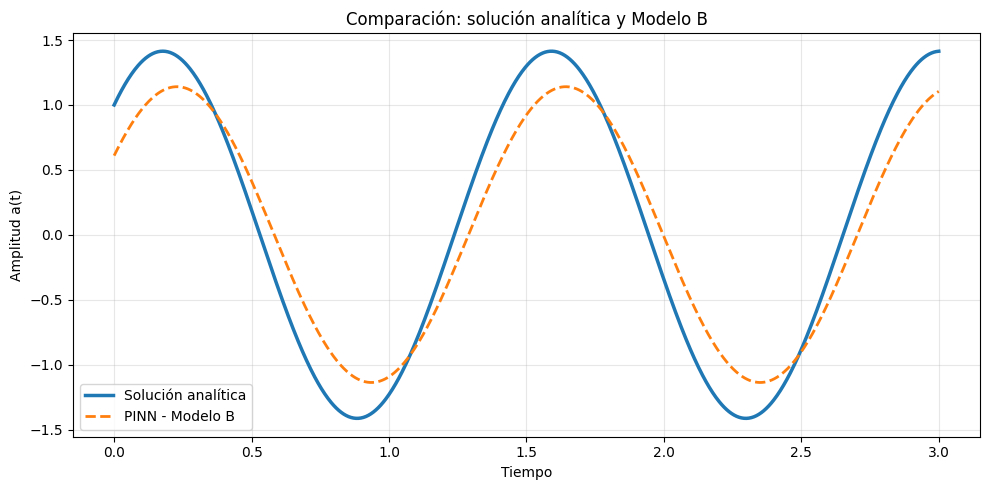

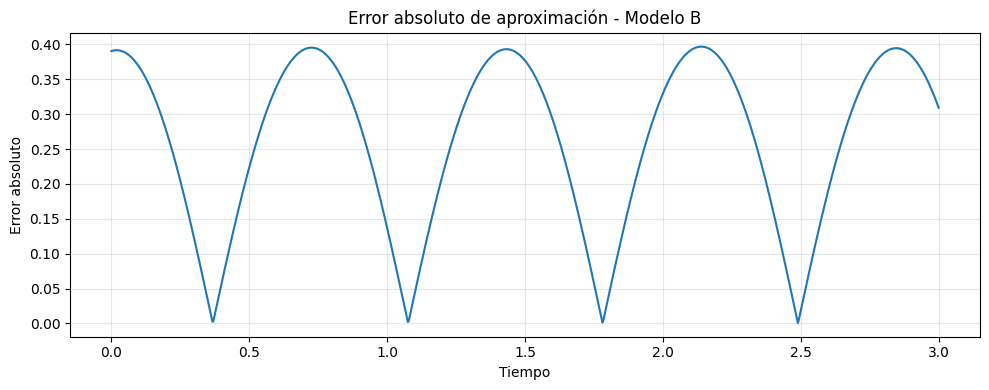

In [14]:

# Utilizamos la misma malla temporal del Modelo A
t_eval_B = np.linspace(0, 3, 1000)

# Solución analítica
a_real_B = a_exacta(t_eval_B)

# Conversión a tensor
t_tensor_B = torch.tensor(
    t_eval_B.reshape(-1, 1),
    dtype=torch.float64,
    device=device
)

# Predicción del Modelo B
modelo_B.eval()

with torch.no_grad():
    a_pred_B = (
        modelo_B(t_tensor_B)
        .cpu()
        .numpy()
        .flatten()
    )

# Error absoluto
error_abs_B = np.abs(a_pred_B - a_real_B)

# Comparación gráfica
plt.figure(figsize=(10, 5))

plt.plot(
    t_eval_B,
    a_real_B,
    label="Solución analítica",
    linewidth=2.5
)

plt.plot(
    t_eval_B,
    a_pred_B,
    "--",
    label="PINN - Modelo B",
    linewidth=2
)

plt.xlabel("Tiempo")
plt.ylabel("Amplitud a(t)")
plt.title("Comparación: solución analítica y Modelo B")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Error absoluto
plt.figure(figsize=(10, 4))

plt.plot(t_eval_B, error_abs_B)

plt.xlabel("Tiempo")
plt.ylabel("Error absoluto")
plt.title("Error absoluto de aproximación - Modelo B")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### 4.4. Refinamiento mediante L-BFGS

El entrenamiento inicial con Adam permitió reducir la función de pérdida, pero la solución obtenida todavía presenta diferencias de amplitud y fase respecto a la solución analítica.

Para mejorar la aproximación, se realiza una segunda etapa de optimización utilizando L-BFGS, partiendo de los parámetros obtenidos con Adam.

Este procedimiento mantiene la arquitectura original y busca reducir el residuo físico y los errores en las condiciones iniciales.


In [15]:

# Guardar pérdida antes del refinamiento
perdida_antes = funcion_perdida(
    modelo_B, t_train
)[0].item()

# Optimizador L-BFGS
optimizador_LBFGS = torch.optim.LBFGS(
    modelo_B.parameters(),
    lr=0.5,
    max_iter=2000,
    tolerance_grad=1e-12,
    tolerance_change=1e-14,
    history_size=100,
    line_search_fn="strong_wolfe"
)

historial_B_LBFGS = []

# Función requerida por L-BFGS
def closure():
    optimizador_LBFGS.zero_grad()

    perdida_total, _, _, _ = funcion_perdida(
        modelo_B,
        t_train
    )

    perdida_total.backward()

    historial_B_LBFGS.append(
        perdida_total.item()
    )

    return perdida_total

# Refinamiento
modelo_B.train()
optimizador_LBFGS.step(closure)

# Evaluación final
total_B, fisica_B, ci1_B, ci2_B = funcion_perdida(
    modelo_B, t_train
)

print("RESULTADOS DEL REFINAMIENTO")
print("-" * 42)
print(f"Pérdida antes:  {perdida_antes:.8e}")
print(f"Pérdida después: {total_B.item():.8e}")
print(f"Residuo físico: {fisica_B.item():.8e}")
print(f"Condición a(0): {ci1_B.item():.8e}")
print(f"Condición a'(0): {ci2_B.item():.8e}")

print("\nParámetros refinados:")
for nombre, parametro in modelo_B.named_parameters():
    print(nombre, parametro.detach().cpu().numpy())


RESULTADOS DEL REFINAMIENTO
------------------------------------------
Pérdida antes:  4.37802461e-01
Pérdida después: 1.07264685e-07
Residuo físico: 1.07259093e-07
Condición a(0): 5.61931370e-13
Condición a'(0): 5.02914777e-12

Parámetros refinados:
A 199.78965896746945
w1 4.442884180713303
w2 0.007078567236571545
b1 0.7853941795434345
b2 -1.744232527126646e-09



### 4.5. Evaluación del Modelo B refinado

Después del refinamiento con L-BFGS, se evalúa nuevamente el Modelo B frente a la solución analítica.

Se comparan las amplitudes temporales y se calcula el error absoluto para determinar si la mejora de la función de pérdida se traduce en una mayor precisión de la solución.

La evaluación utiliza el mismo intervalo temporal y los mismos puntos empleados para el Modelo A.


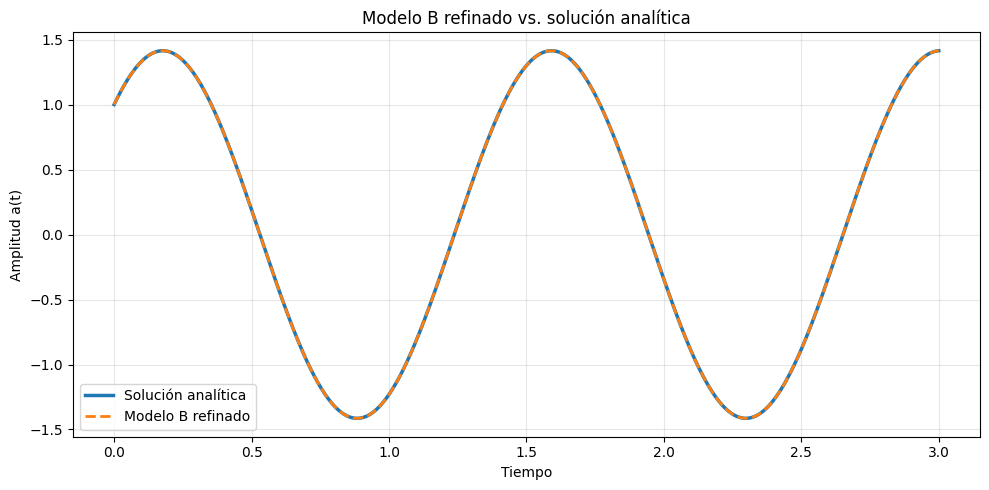

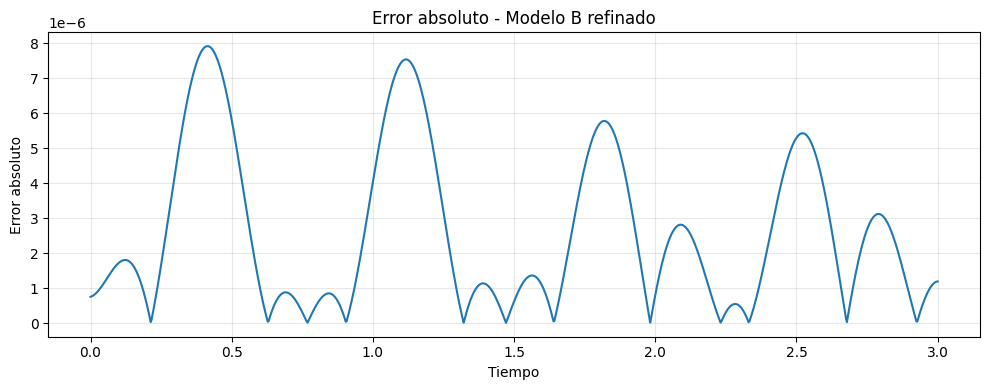

In [16]:

# Predicción refinada del Modelo B
modelo_B.eval()

with torch.no_grad():
    a_pred_B = (
        modelo_B(t_tensor_B)
        .cpu()
        .numpy()
        .flatten()
    )

# Error absoluto actualizado
error_abs_B = np.abs(a_pred_B - a_real_B)

# Comparación de soluciones
plt.figure(figsize=(10, 5))

plt.plot(
    t_eval_B,
    a_real_B,
    label="Solución analítica",
    linewidth=2.5
)

plt.plot(
    t_eval_B,
    a_pred_B,
    "--",
    label="Modelo B refinado",
    linewidth=2
)

plt.xlabel("Tiempo")
plt.ylabel("Amplitud a(t)")
plt.title("Modelo B refinado vs. solución analítica")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Error absoluto
plt.figure(figsize=(10, 4))

plt.plot(t_eval_B, error_abs_B)

plt.xlabel("Tiempo")
plt.ylabel("Error absoluto")
plt.title("Error absoluto - Modelo B refinado")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### 4.6. Cuantificación de errores del Modelo B

Se calculan el error absoluto medio (MAE), la raíz del error cuadrático medio (RMSE), el error relativo global y el error absoluto máximo.

Estas métricas permiten evaluar cuantitativamente la precisión alcanzada después del refinamiento y compararla con el Modelo A.


In [17]:

# Métricas del Modelo B refinado
diferencia_B = a_pred_B - a_real_B

mae_B = np.mean(np.abs(diferencia_B))
rmse_B = np.sqrt(np.mean(diferencia_B**2))

error_relativo_B = (
    np.linalg.norm(diferencia_B)
    / np.linalg.norm(a_real_B)
) * 100

error_maximo_B = np.max(np.abs(diferencia_B))

print("RESULTADOS DEL MODELO B REFINADO")
print("-" * 45)
print(f"MAE:                   {mae_B:.8e}")
print(f"RMSE:                  {rmse_B:.8e}")
print(f"Error relativo global: {error_relativo_B:.6f} %")
print(f"Error absoluto máximo: {error_maximo_B:.8e}")

print("\nCOMPARACIÓN DE AMBOS MODELOS")
print("-" * 58)
print(f"{'Métrica':<24} {'Modelo A':>14} {'Modelo B':>14}")
print("-" * 58)
print(f"{'MAE':<24} {mae_A:>14.6e} {mae_B:>14.6e}")
print(f"{'RMSE':<24} {rmse_A:>14.6e} {rmse_B:>14.6e}")
print(f"{'Error relativo (%)':<24} {error_relativo_A:>14.6f} {error_relativo_B:>14.6f}")
print(f"{'Error máximo':<24} {error_maximo_A:>14.6e} {error_maximo_B:>14.6e}")


RESULTADOS DEL MODELO B REFINADO
---------------------------------------------
MAE:                   2.56953832e-06
RMSE:                  3.40292661e-06
Error relativo global: 0.000334 %
Error absoluto máximo: 7.91386286e-06

COMPARACIÓN DE AMBOS MODELOS
----------------------------------------------------------
Métrica                        Modelo A       Modelo B
----------------------------------------------------------
MAE                        2.293976e-04   2.569538e-06
RMSE                       2.759287e-04   3.402927e-06
Error relativo (%)             0.027106       0.000334
Error máximo               4.860346e-04   7.913863e-06



### 4.7. Conservación de la energía mecánica del Modelo B

Se evalúa la conservación de la energía mecánica utilizando la amplitud temporal obtenida con el Modelo B refinado.

La energía reducida de la membrana está dada por:

$$
E_\theta(t)=\frac18[a_\theta'(t)]^2+\frac{\pi^2}{4}[a_\theta(t)]^2.
$$

Para la solución exacta, la energía permanece constante:

$$
E_{\mathrm{exacta}}=\frac{\pi^2}{2}.
$$

Se calculará la energía predicha mediante diferenciación automática y se determinarán el error relativo medio, el error relativo máximo y la variación relativa de energía.

Esto permitirá evaluar si el Modelo B reproduce correctamente el carácter conservativo de la ecuación de ondas.


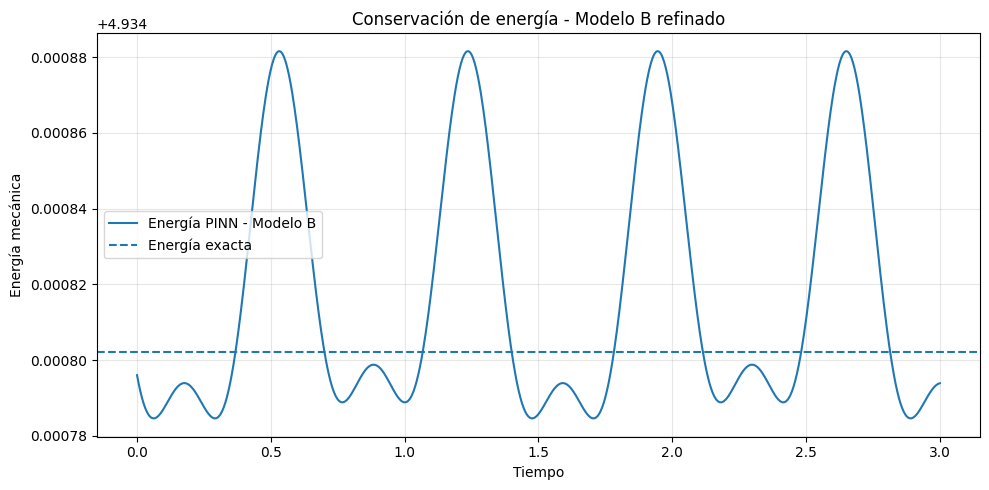

ENERGÍA MECÁNICA - MODELO B
---------------------------------------------
Energía exacta: 4.93480220
Energía media PINN: 4.93481663
Error relativo medio: 0.00053608 %
Error relativo máximo: 0.00160771 %
Variación relativa de energía: 0.00196427 %


In [18]:

# Malla temporal para evaluar la energía
t_energia_B = torch.linspace(
    0, 3, 1000,
    dtype=torch.float64,
    device=device
).reshape(-1, 1).requires_grad_(True)

# Amplitud temporal del Modelo B
modelo_B.eval()
a_energia_B = modelo_B(t_energia_B)

# Primera derivada temporal
da_energia_B = torch.autograd.grad(
    outputs=a_energia_B,
    inputs=t_energia_B,
    grad_outputs=torch.ones_like(a_energia_B),
    create_graph=False
)[0]

# Energía mecánica predicha
energia_B_tensor = (
    (1 / 8) * da_energia_B**2
    + (np.pi**2 / 4) * a_energia_B**2
)

E_B = (
    energia_B_tensor
    .detach()
    .cpu()
    .numpy()
    .flatten()
)

# Energía exacta
E_exacta = np.pi**2 / 2

# Error relativo de energía
error_energia_B = (
    np.abs(E_B - E_exacta) / E_exacta
) * 100

# Variación relativa
variacion_energia_B = (
    (np.max(E_B) - np.min(E_B))
    / E_exacta
) * 100

# Gráfica
plt.figure(figsize=(10, 5))

plt.plot(
    t_eval_B,
    E_B,
    label="Energía PINN - Modelo B"
)

plt.axhline(
    E_exacta,
    linestyle="--",
    label="Energía exacta"
)

plt.xlabel("Tiempo")
plt.ylabel("Energía mecánica")
plt.title("Conservación de energía - Modelo B refinado")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Resultados numéricos
print("ENERGÍA MECÁNICA - MODELO B")
print("-" * 45)

print(f"Energía exacta: {E_exacta:.8f}")
print(f"Energía media PINN: {np.mean(E_B):.8f}")

print(
    f"Error relativo medio: "
    f"{np.mean(error_energia_B):.8f} %"
)

print(
    f"Error relativo máximo: "
    f"{np.max(error_energia_B):.8f} %"
)

print(
    f"Variación relativa de energía: "
    f"{variacion_energia_B:.8f} %"
)



## 5. Comparación de las arquitecturas PINN

Se comparan las soluciones obtenidas mediante los Modelos A y B con la solución analítica de la ecuación de ondas.

El Modelo A utiliza una suma de dos funciones sinusoidales, mientras que el Modelo B emplea una composición de activaciones sinusoidales.

Se analizarán las diferencias de precisión y las características de convergencia, considerando que el Modelo B requirió una etapa adicional de refinamiento mediante L-BFGS.


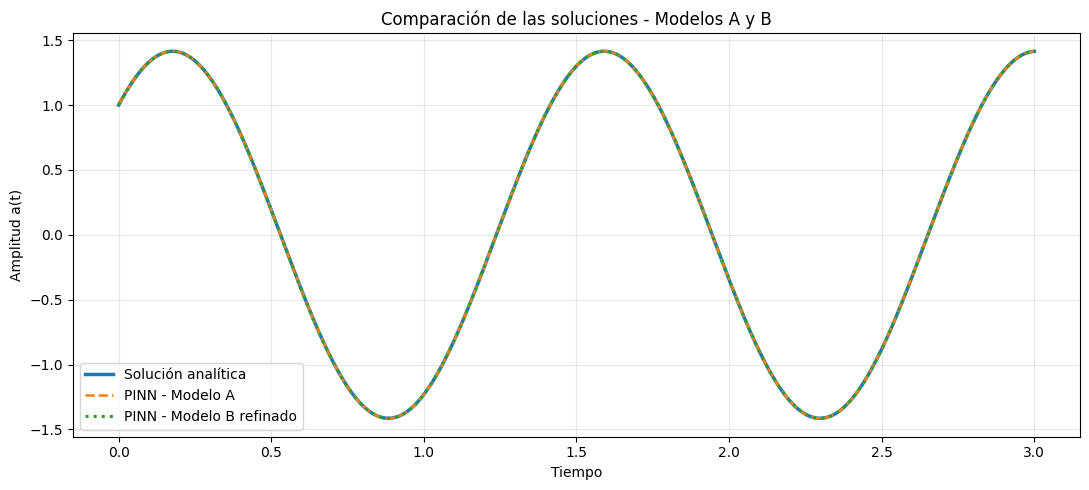

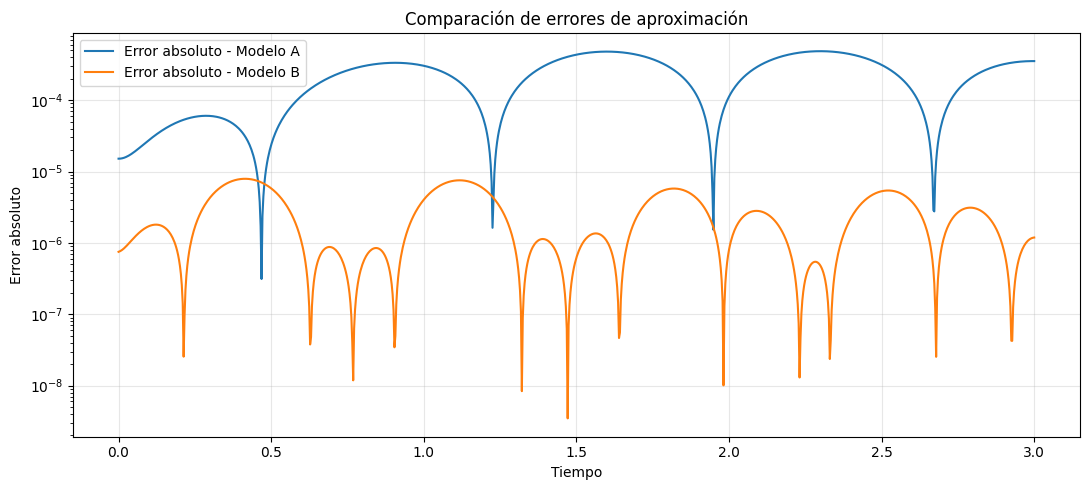

In [19]:

# Comparación de las tres soluciones
plt.figure(figsize=(11, 5))

plt.plot(
    t_eval,
    a_real,
    label="Solución analítica",
    linewidth=2.5
)

plt.plot(
    t_eval,
    a_pred,
    "--",
    label="PINN - Modelo A",
    linewidth=1.8
)

plt.plot(
    t_eval_B,
    a_pred_B,
    ":",
    label="PINN - Modelo B refinado",
    linewidth=2.2
)

plt.xlabel("Tiempo")
plt.ylabel("Amplitud a(t)")
plt.title("Comparación de las soluciones - Modelos A y B")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Comparación de errores absolutos
plt.figure(figsize=(11, 5))

plt.semilogy(
    t_eval,
    np.maximum(np.abs(a_pred - a_real), 1e-16),
    label="Error absoluto - Modelo A"
)

plt.semilogy(
    t_eval_B,
    np.maximum(np.abs(a_pred_B - a_real_B), 1e-16),
    label="Error absoluto - Modelo B"
)

plt.xlabel("Tiempo")
plt.ylabel("Error absoluto")
plt.title("Comparación de errores de aproximación")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### 5.1. Comparación de la conservación de energía

Se comparan las energías mecánicas predichas por ambas arquitecturas con el valor exacto:

$$
E_{\mathrm{exacta}}=\frac{\pi^2}{2}.
$$

Para facilitar la visualización de las diferencias, se representa el error relativo porcentual de energía:

$$
\varepsilon_E(t)=
\frac{|E_\theta(t)-E_{\mathrm{exacta}}|}
{E_{\mathrm{exacta}}}\times100\%.
$$

Esta representación permite comparar directamente las desviaciones energéticas de ambos modelos, incluso cuando sus errores tienen órdenes de magnitud diferentes.


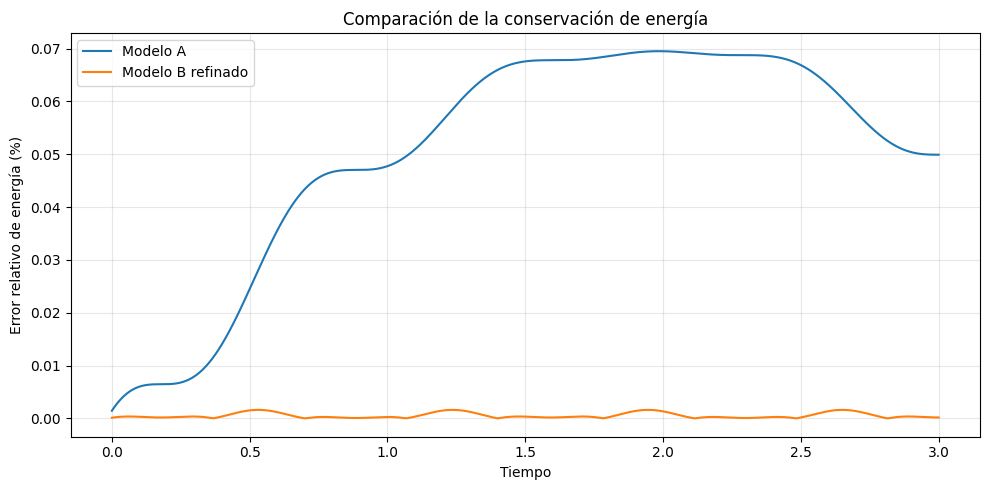

COMPARACIÓN ENERGÉTICA
--------------------------------------------------
Error energético medio Modelo A: 0.05057757 %
Error energético medio Modelo B: 0.00053608 %
Variación energética Modelo A: 0.06804987 %
Variación energética Modelo B: 0.00196427 %


In [20]:

# Errores relativos de energía
error_E_A = np.abs(E_A - E_exacta) / E_exacta * 100
error_E_B = np.abs(E_B - E_exacta) / E_exacta * 100

# Comparación gráfica
plt.figure(figsize=(10, 5))

plt.plot(
    t_eval,
    error_E_A,
    label="Modelo A"
)

plt.plot(
    t_eval_B,
    error_E_B,
    label="Modelo B refinado"
)

plt.xlabel("Tiempo")
plt.ylabel("Error relativo de energía (%)")
plt.title("Comparación de la conservación de energía")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Resultados
print("COMPARACIÓN ENERGÉTICA")
print("-" * 50)

print(
    f"Error energético medio Modelo A: "
    f"{np.mean(error_E_A):.8f} %"
)

print(
    f"Error energético medio Modelo B: "
    f"{np.mean(error_E_B):.8f} %"
)

print(
    f"Variación energética Modelo A: "
    f"{(np.max(E_A)-np.min(E_A))/E_exacta*100:.8f} %"
)

print(
    f"Variación energética Modelo B: "
    f"{(np.max(E_B)-np.min(E_B))/E_exacta*100:.8f} %"
)



## 6. Discusión de resultados

Los resultados muestran que ambas arquitecturas pueden aproximar la solución de la ecuación de ondas para la membrana cuadrada.

El Modelo A presentó una convergencia favorable utilizando únicamente Adam. Su estructura, basada en la suma de dos funciones sinusoidales, es especialmente adecuada para representar la solución armónica del problema.

El Modelo B mostró inicialmente mayores dificultades de convergencia, con errores visibles de amplitud y fase. Sin embargo, el refinamiento mediante L-BFGS redujo considerablemente la pérdida física y permitió obtener una aproximación más precisa que la del Modelo A entrenado.

La comparación de energía confirma que ambas soluciones reproducen aproximadamente el carácter conservativo de la membrana, aunque el Modelo B refinado presenta desviaciones mucho menores.

Estos resultados evidencian la importancia de la arquitectura neuronal, la inicialización de los parámetros y el método de optimización en el entrenamiento de redes informadas por la física.


In [21]:

import pandas as pd

# Métricas energéticas
energia_media_A = np.mean(error_E_A)
energia_media_B = np.mean(error_E_B)

variacion_A = (
    (np.max(E_A) - np.min(E_A)) / E_exacta
) * 100

variacion_B = (
    (np.max(E_B) - np.min(E_B)) / E_exacta
) * 100

# Tabla comparativa
resultados = pd.DataFrame({
    "Métrica": [
        "MAE",
        "RMSE",
        "Error relativo global (%)",
        "Error absoluto máximo",
        "Error energético medio (%)",
        "Variación de energía (%)"
    ],
    "Modelo A": [
        mae_A,
        rmse_A,
        error_relativo_A,
        error_maximo_A,
        energia_media_A,
        variacion_A
    ],
    "Modelo B refinado": [
        mae_B,
        rmse_B,
        error_relativo_B,
        error_maximo_B,
        energia_media_B,
        variacion_B
    ]
})

display(
    resultados.style.format({
        "Modelo A": "{:.8e}",
        "Modelo B refinado": "{:.8e}"
    })
)


,Métrica,Modelo A,Modelo B refinado
0,MAE,2.29397612e-04,2.56953832e-06
1,RMSE,2.75928740e-04,3.40292661e-06
2,Error relativo global (%),2.71060730e-02,3.34289124e-04
3,Error absoluto máximo,4.86034559e-04,7.91386286e-06
4,Error energético medio (%),5.05775667e-02,5.36081312e-04
5,Variación de energía (%),6.80498728e-02,1.96427277e-03



## 7. Conclusiones

En este trabajo se implementaron dos arquitecturas PINN para aproximar la solución de la ecuación de ondas bidimensional de una membrana cuadrada con bordes fijos.

La separación de variables permitió reducir el problema a una ecuación diferencial ordinaria para la amplitud temporal. Esta reducción facilitó el entrenamiento de las redes y la comparación con la solución analítica.

El Modelo A consiguió una buena aproximación utilizando únicamente Adam, con un error relativo global del 0.027106 %. Su estructura sinusoidal resultó apropiada para describir las oscilaciones de la membrana.

El Modelo B presentó inicialmente dificultades para reproducir la amplitud y las condiciones iniciales. Sin embargo, después del refinamiento con L-BFGS, alcanzó un error relativo global del 0.000334 %, inferior al obtenido con el Modelo A.

El análisis energético mostró que ambas arquitecturas conservan aproximadamente la energía mecánica, aunque el Modelo B refinado presentó desviaciones considerablemente menores.

En conclusión, las PINN permiten incorporar directamente las leyes físicas al entrenamiento de una red neuronal. Los resultados también muestran que una arquitectura más compleja no garantiza por sí sola una mejor solución: la elección del optimizador y el ajuste de los parámetros pueden ser determinantes para alcanzar una aproximación precisa.



## 8. Refinamiento del Modelo A y comparación final de las arquitecturas

Para realizar una comparación más equilibrada entre las dos arquitecturas PINN, se aplica una segunda etapa de optimización mediante L-BFGS al Modelo A, utilizando los parámetros previamente obtenidos con Adam.

Anteriormente, el Modelo B presentó dificultades de convergencia con Adam, pero mejoró considerablemente después del refinamiento con L-BFGS. Por esta razón, resulta importante comprobar si el Modelo A también puede reducir sus errores al utilizar el mismo procedimiento.

Se mantiene la arquitectura original:

$$
a_A(t)=\sum_{j=1}^{2}A_j\sin(w_jt+b_j).
$$

La función de pérdida continúa siendo:

$$
\mathcal{L}=
\frac{1}{N_r}\sum_{k=1}^{N_r}
[a_\theta''(t_k)+2\pi^2a_\theta(t_k)]^2
+[a_\theta(0)-1]^2
+[a_\theta'(0)-\sqrt{2}\pi]^2.
$$

Después del refinamiento se calcularán nuevamente los errores MAE, RMSE y relativo global. También se evaluará la conservación de energía mediante:

$$
E_\theta(t)=\frac18[a_\theta'(t)]^2+
\frac{\pi^2}{4}[a_\theta(t)]^2.
$$

Finalmente, se compararán ambos modelos utilizando sus resultados refinados, con el propósito de analizar la influencia de la arquitectura y del método de optimización en la precisión de las soluciones.

Aunque ambos modelos utilizarán Adam y L-BFGS, sus inicializaciones y trayectorias de optimización seguirán siendo diferentes. Por tanto, la comparación será más equilibrada, pero no constituirá una demostración definitiva de superioridad de una arquitectura sobre otra.


REFINAMIENTO DEL MODELO A
--------------------------------------------------
Pérdida antes:   2.56932706e-06
Pérdida después: 1.89841655e-15

COMPARACIÓN FINAL: AMBOS MODELOS REFINADOS


,Modelo A refinado,Modelo B refinado
MAE,1.89261973e-08,2.56953832e-06
RMSE,2.09644313e-08,3.40292661e-06
Error relativo (%),2.05945710e-06,3.34289124e-04
Error máximo,3.42311872e-08,7.91386286e-06
Error energético medio (%),2.70311544e-06,5.36081312e-04
Variación de energía (%),1.72860689e-06,1.96427277e-03


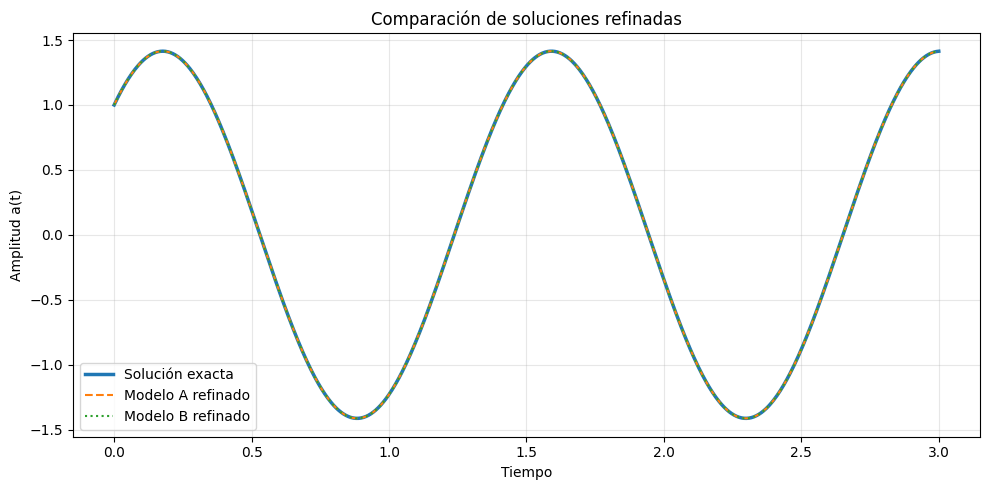

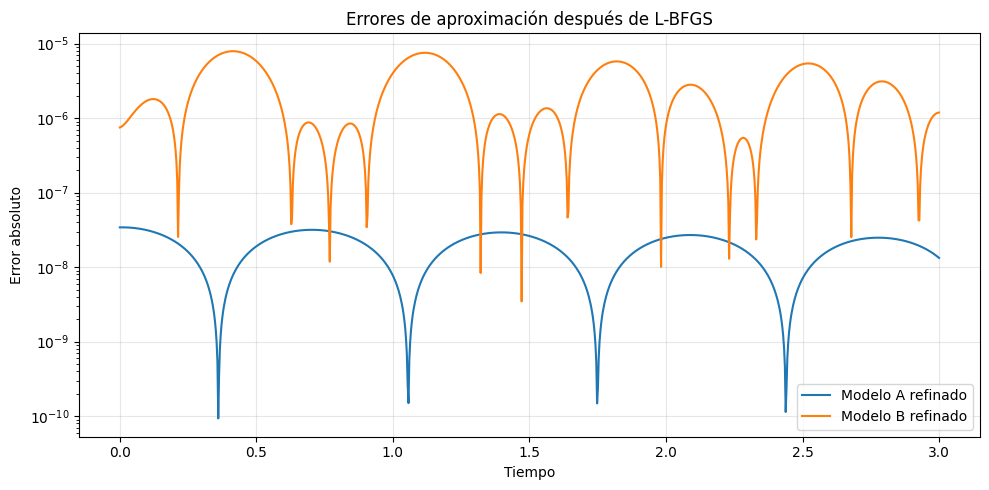

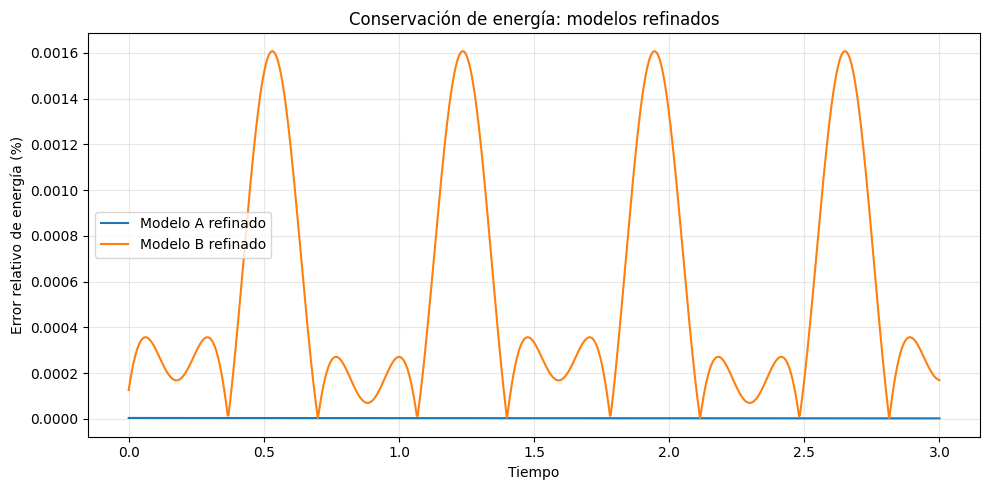


RESULTADO FINAL
--------------------------------------------------
El Modelo A refinado obtuvo el menor RMSE.
RMSE Modelo A: 2.09644313e-08
RMSE Modelo B: 3.40292661e-06


In [22]:

# ============================================================
# REFINAMIENTO DEL MODELO A CON L-BFGS
# ============================================================

# Pérdida antes del refinamiento
perdida_A_antes = funcion_perdida(modelo_A, t_train)[0].item()

# Configurar L-BFGS con los mismos hiperparámetros del Modelo B
optimizador_A_LBFGS = torch.optim.LBFGS(
    modelo_A.parameters(),
    lr=0.5,
    max_iter=2000,
    tolerance_grad=1e-12,
    tolerance_change=1e-14,
    history_size=100,
    line_search_fn="strong_wolfe"
)

historial_A_LBFGS = []

def closure_A():
    optimizador_A_LBFGS.zero_grad()

    perdida, _, _, _ = funcion_perdida(modelo_A, t_train)

    perdida.backward()
    historial_A_LBFGS.append(perdida.item())

    return perdida

modelo_A.train()
optimizador_A_LBFGS.step(closure_A)

perdida_A_despues = funcion_perdida(modelo_A, t_train)[0].item()

print("REFINAMIENTO DEL MODELO A")
print("-" * 50)
print(f"Pérdida antes:   {perdida_A_antes:.8e}")
print(f"Pérdida después: {perdida_A_despues:.8e}")

# ============================================================
# PREDICCIONES REFINADAS Y MÉTRICAS
# ============================================================

modelo_A.eval()
modelo_B.eval()

with torch.no_grad():
    a_pred_A_final = modelo_A(t_tensor).cpu().numpy().flatten()
    a_pred_B_final = modelo_B(t_tensor).cpu().numpy().flatten()

def calcular_metricas(pred, exacta):
    diferencia = pred - exacta
    return {
        "MAE": np.mean(np.abs(diferencia)),
        "RMSE": np.sqrt(np.mean(diferencia**2)),
        "Error relativo (%)":
            100 * np.linalg.norm(diferencia) / np.linalg.norm(exacta),
        "Error máximo": np.max(np.abs(diferencia))
    }

metricas_A_final = calcular_metricas(a_pred_A_final, a_real)
metricas_B_final = calcular_metricas(a_pred_B_final, a_real)

# ============================================================
# ENERGÍA MECÁNICA DE AMBOS MODELOS
# ============================================================

def calcular_energia(modelo, tiempos):
    t = torch.tensor(
        tiempos.reshape(-1, 1),
        dtype=torch.float64,
        device=device,
        requires_grad=True
    )

    a = modelo(t)

    da = torch.autograd.grad(
        a, t,
        grad_outputs=torch.ones_like(a),
        create_graph=False
    )[0]

    energia = (da**2) / 8 + (np.pi**2 / 4) * a**2

    return energia.detach().cpu().numpy().flatten()

E_A_final = calcular_energia(modelo_A, t_eval)
E_B_final = calcular_energia(modelo_B, t_eval)

for nombre, E, metricas in [
    ("Modelo A refinado", E_A_final, metricas_A_final),
    ("Modelo B refinado", E_B_final, metricas_B_final)
]:
    metricas["Error energético medio (%)"] = (
        100 * np.mean(np.abs(E - E_exacta)) / E_exacta
    )
    metricas["Variación de energía (%)"] = (
        100 * (E.max() - E.min()) / E_exacta
    )

# ============================================================
# TABLA COMPARATIVA FINAL
# ============================================================

import pandas as pd

tabla_refinada = pd.DataFrame({
    "Modelo A refinado": metricas_A_final,
    "Modelo B refinado": metricas_B_final
})

print("\nCOMPARACIÓN FINAL: AMBOS MODELOS REFINADOS")
display(tabla_refinada.style.format("{:.8e}"))

# ============================================================
# GRÁFICAS COMPARATIVAS
# ============================================================

# 1. Soluciones temporales
plt.figure(figsize=(10, 5))
plt.plot(t_eval, a_real, label="Solución exacta", linewidth=2.5)
plt.plot(t_eval, a_pred_A_final, "--", label="Modelo A refinado")
plt.plot(t_eval, a_pred_B_final, ":", label="Modelo B refinado")
plt.xlabel("Tiempo")
plt.ylabel("Amplitud a(t)")
plt.title("Comparación de soluciones refinadas")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Errores absolutos
plt.figure(figsize=(10, 5))
plt.semilogy(
    t_eval,
    np.maximum(np.abs(a_pred_A_final - a_real), 1e-16),
    label="Modelo A refinado"
)
plt.semilogy(
    t_eval,
    np.maximum(np.abs(a_pred_B_final - a_real), 1e-16),
    label="Modelo B refinado"
)
plt.xlabel("Tiempo")
plt.ylabel("Error absoluto")
plt.title("Errores de aproximación después de L-BFGS")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Errores relativos de energía
plt.figure(figsize=(10, 5))
plt.plot(
    t_eval,
    100 * np.abs(E_A_final - E_exacta) / E_exacta,
    label="Modelo A refinado"
)
plt.plot(
    t_eval,
    100 * np.abs(E_B_final - E_exacta) / E_exacta,
    label="Modelo B refinado"
)
plt.xlabel("Tiempo")
plt.ylabel("Error relativo de energía (%)")
plt.title("Conservación de energía: modelos refinados")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# IDENTIFICAR EL MENOR ERROR
# ============================================================

rmse_A_final = metricas_A_final["RMSE"]
rmse_B_final = metricas_B_final["RMSE"]

print("\nRESULTADO FINAL")
print("-" * 50)

if rmse_A_final < rmse_B_final:
    print("El Modelo A refinado obtuvo el menor RMSE.")
elif rmse_B_final < rmse_A_final:
    print("El Modelo B refinado obtuvo el menor RMSE.")
else:
    print("Ambos modelos obtuvieron el mismo RMSE.")

print(f"RMSE Modelo A: {rmse_A_final:.8e}")
print(f"RMSE Modelo B: {rmse_B_final:.8e}")



## 9. Análisis y conclusiones finales

### Análisis de los resultados

En este trabajo se implementaron dos arquitecturas de redes neuronales informadas por la física (PINN) para aproximar el desplazamiento transversal de una membrana cuadrada con bordes fijos. Mediante la separación de variables, la ecuación de ondas bidimensional se redujo a una ecuación diferencial ordinaria para la amplitud temporal:

$$
a''(t)+2\pi^2a(t)=0.
$$

La solución analítica utilizada como referencia fue:

$$
a(t)=\cos(\sqrt{2}\pi t)+\sin(\sqrt{2}\pi t).
$$

Inicialmente, el Modelo A, formado por dos neuronas sinusoidales en una misma capa, presentó una convergencia favorable utilizando Adam. Alcanzó un error relativo global del 0.027106 % y un RMSE de $2.7593\times10^{-4}$.

El Modelo B, compuesto por dos capas sinusoidales consecutivas, presentó mayores dificultades durante el entrenamiento inicial. Sin embargo, después de aplicar L-BFGS, su pérdida disminuyó de aproximadamente $0.438$ a $1.073\times10^{-7}$, alcanzando un error relativo global del 0.000334 % y un RMSE de $3.4029\times10^{-6}$.

Posteriormente, se aplicó L-BFGS también al Modelo A para realizar una comparación más equilibrada. La gráfica final mostró que ambas arquitecturas refinadas reproducen prácticamente la misma evolución temporal que la solución analítica, con buena concordancia en amplitud, frecuencia y fase.

### Conservación de energía

La energía mecánica de la membrana está dada por:

$$
E(t)=\frac18[a'(t)]^2+\frac{\pi^2}{4}[a(t)]^2.
$$

Para la solución exacta:

$$
E_{\mathrm{exacta}}=\frac{\pi^2}{2}\approx4.93480220.
$$

Antes del refinamiento adicional, el Modelo A presentó un error energético relativo medio del 0.050578 % y una variación relativa de energía del 0.068050 %.

El Modelo B refinado mostró desviaciones energéticas considerablemente menores, lo que indica una mejor reproducción de la dinámica conservativa en esa etapa del experimento.

La comparación energética definitiva debe realizarse utilizando las energías recalculadas después del refinamiento de ambos modelos.

### Conclusiones

Los resultados demuestran que ambas arquitecturas PINN pueden aproximar satisfactoriamente la solución de la ecuación de ondas para una membrana cuadrada.

El Modelo A mostró una ventaja inicial en la facilidad de entrenamiento, debido a que su estructura de suma de funciones sinusoidales es adecuada para representar oscilaciones armónicas.

El Modelo B requirió un refinamiento adicional para alcanzar una alta precisión. Esto evidencia que una arquitectura con mayor profundidad no necesariamente presenta una optimización más sencilla.

La aplicación de L-BFGS mejoró el comportamiento de las redes sin modificar sus arquitecturas originales. La comparación gráfica final confirma que ambos modelos refinados reproducen adecuadamente la dinámica temporal.

En términos físicos, el análisis de energía permitió comprobar que las soluciones neuronales reproducen aproximadamente el carácter conservativo del sistema. Las pequeñas desviaciones observadas se relacionan con el cumplimiento aproximado de la ecuación diferencial.

En conclusión, las PINN constituyen una herramienta útil para resolver ecuaciones diferenciales incorporando directamente las leyes físicas y las condiciones iniciales al proceso de entrenamiento. Este ejercicio también muestra que la elección del optimizador, la arquitectura y la inicialización de parámetros influyen significativamente en la precisión alcanzada.


In [23]:

import numpy as np
import pandas as pd

# =====================================================
# 1. RESULTADOS DE AMBOS MODELOS REFINADOS
# =====================================================

resultados_finales = pd.DataFrame({
    "Modelo A refinado": metricas_A_final,
    "Modelo B refinado": metricas_B_final
})

print("TABLA FINAL DE RESULTADOS")
print("=" * 65)

display(resultados_finales.style.format("{:.8e}"))

# =====================================================
# 2. COMPARACIÓN DE PRECISIÓN
# =====================================================

rmse_A = metricas_A_final["RMSE"]
rmse_B = metricas_B_final["RMSE"]

energia_A = metricas_A_final["Error energético medio (%)"]
energia_B = metricas_B_final["Error energético medio (%)"]

variacion_A = metricas_A_final["Variación de energía (%)"]
variacion_B = metricas_B_final["Variación de energía (%)"]

mejor_rmse = (
    "Modelo A" if rmse_A < rmse_B
    else "Modelo B" if rmse_B < rmse_A
    else "Ambos modelos"
)

mejor_energia = (
    "Modelo A" if energia_A < energia_B
    else "Modelo B" if energia_B < energia_A
    else "Ambos modelos"
)

print("\nCOMPARACIÓN CUANTITATIVA")
print("-" * 55)
print(f"Menor RMSE: {mejor_rmse}")
print(f"Menor error energético medio: {mejor_energia}")
print(f"RMSE A: {rmse_A:.8e}")
print(f"RMSE B: {rmse_B:.8e}")
print(f"Error energético medio A: {energia_A:.8f} %")
print(f"Error energético medio B: {energia_B:.8f} %")
print(f"Variación energética A: {variacion_A:.8f} %")
print(f"Variación energética B: {variacion_B:.8f} %")

# =====================================================
# 3. CONCLUSIÓN AUTOMÁTICA
# =====================================================

print("\nCONCLUSIÓN FINAL")
print("=" * 65)

print(
    "Ambas arquitecturas PINN reprodujeron la evolución "
    "temporal de la membrana y aproximaron la conservación "
    "de la energía mecánica."
)

print(
    f"Después del refinamiento con L-BFGS, {mejor_rmse} "
    "obtuvo el menor error cuadrático medio."
)

print(
    f"En cuanto a la energía, {mejor_energia} presentó "
    "el menor error relativo medio."
)

print(
    "El Modelo A mostró una convergencia inicial favorable "
    "con Adam, mientras que el Modelo B necesitó un "
    "refinamiento adicional para alcanzar una alta precisión."
)

print(
    "Los resultados evidencian que tanto la arquitectura "
    "neuronal como la estrategia de optimización influyen "
    "en la calidad de las soluciones obtenidas."
)


TABLA FINAL DE RESULTADOS


,Modelo A refinado,Modelo B refinado
MAE,1.89261973e-08,2.56953832e-06
RMSE,2.09644313e-08,3.40292661e-06
Error relativo (%),2.05945710e-06,3.34289124e-04
Error máximo,3.42311872e-08,7.91386286e-06
Error energético medio (%),2.70311544e-06,5.36081312e-04
Variación de energía (%),1.72860689e-06,1.96427277e-03



COMPARACIÓN CUANTITATIVA
-------------------------------------------------------
Menor RMSE: Modelo A
Menor error energético medio: Modelo A
RMSE A: 2.09644313e-08
RMSE B: 3.40292661e-06
Error energético medio A: 0.00000270 %
Error energético medio B: 0.00053608 %
Variación energética A: 0.00000173 %
Variación energética B: 0.00196427 %

CONCLUSIÓN FINAL
Ambas arquitecturas PINN reprodujeron la evolución temporal de la membrana y aproximaron la conservación de la energía mecánica.
Después del refinamiento con L-BFGS, Modelo A obtuvo el menor error cuadrático medio.
En cuanto a la energía, Modelo A presentó el menor error relativo medio.
El Modelo A mostró una convergencia inicial favorable con Adam, mientras que el Modelo B necesitó un refinamiento adicional para alcanzar una alta precisión.
Los resultados evidencian que tanto la arquitectura neuronal como la estrategia de optimización influyen en la calidad de las soluciones obtenidas.
